# 코나비즈 가맹점 분류 모델 (ML)

**상호명(문자열) → 코나비즈 분류 + 확신도 + 근거 업종**

| 분류 | 포인트 | 대표 업종 |
|---|---|---|
| meal | 식대P | 일반음식점 · 커피전문점 · 도서 · 학원 |
| fitness | 체력단련P | 체력단련 · 골프 · 병원 · 약국 |
| welfare | 복지P | 전용 포인트가 없는 가맹점 (기본 차감) |
| expense | 법인경비P | 사무용품 · 출장(숙박 · 항공 · 교통) |
| restricted | 제한 업종 | 유흥주점 (결제 차단) |

- 데이터: 공공데이터포털 15083033 · 소상공인시장진흥공단 상가(상권)정보 **서울 2026-06** (554,092행)
- 방법: 상호명 글자 n-gram TF-IDF + 로지스틱 회귀. **업종(근거 업종 90개)을 예측**한 뒤 업종 확률을 코나비즈 분류별로 더해 확신도로 씀 → 근거 업종을 함께 설명할 수 있음
- 유흥주점 계열은 이름만으로 구분이 어려워 **키워드 규칙**을 먼저 적용 (서비스에서). 아래 모델 성능은 **규칙을 뺀 모델만의 점수**

In [1]:
import sys, time, io, json, platform
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import joblib
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

ML_DIR = Path.cwd()
sys.path.insert(0, str(ML_DIR)); sys.path.insert(0, str(ML_DIR.parent))
from prepare import load_raw, build_names, DATA_CSV
from category_map import SMALL_MAP
from app.ml_rules import CATEGORIES, RESTRICTED_KEYWORDS, normalize, rule_category, classify

# 한글 폰트 (Windows: 맑은 고딕) — 없으면 설치된 한글 폰트 중 하나
KOREAN_FONTS = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]
installed = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in KOREAN_FONTS if f in installed), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 40)

CAT_KO = {"meal": "식대P", "fitness": "체력단련P", "welfare": "복지P", "expense": "법인경비P", "restricted": "제한"}
CAT_COLOR = {"meal": "#0E7490", "fitness": "#16A34A", "welfare": "#7C3AED", "expense": "#D97706", "restricted": "#DC2626"}
SEED = 42
print("python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| 폰트", plt.rcParams["font.family"])

python 3.12.9 | scikit-learn 1.9.1 | pandas 3.0.6 | 폰트 ['Malgun Gothic']


## 1. 데이터 불러오기 · 정리
원본 CSV는 읽기만 함. 정규화 이름(소문자 · 공백/특수문자/법인표기 제거) 단위로 합쳐 체인점은 한 표만 셈

In [2]:
t = time.time()
raw = load_raw()
names, stats = build_names(raw)
print(f"{time.time() - t:.0f}초")
pd.Series({
    "원본 행": stats["rows"],
    "제외 — 이름 자리에 업종명·업소명없음": stats["placeholder"],
    "제외 — 정규화 후 2글자 미만": stats["short"],
    "두 분류 이상에 걸친 이름": stats["conflict_names"],
    "제외 — 다수 분류 비율 60% 미만": stats["dropped_low_agree"],
    "학습 샘플 (고유 이름)": stats["names"],
    "근거 업종 수": names["unit"].nunique(),
    "그룹(앞 3글자) 수": names["group"].nunique(),
}, name="값").to_frame()

13초


,값
원본 행,554092
제외 — 이름 자리에 업종명·업소명없음,1604
제외 — 정규화 후 2글자 미만,1803
두 분류 이상에 걸친 이름,7420
제외 — 다수 분류 비율 60% 미만,4009
학습 샘플 (고유 이름),434387
근거 업종 수,90
그룹(앞 3글자) 수,228654


## 2. EDA

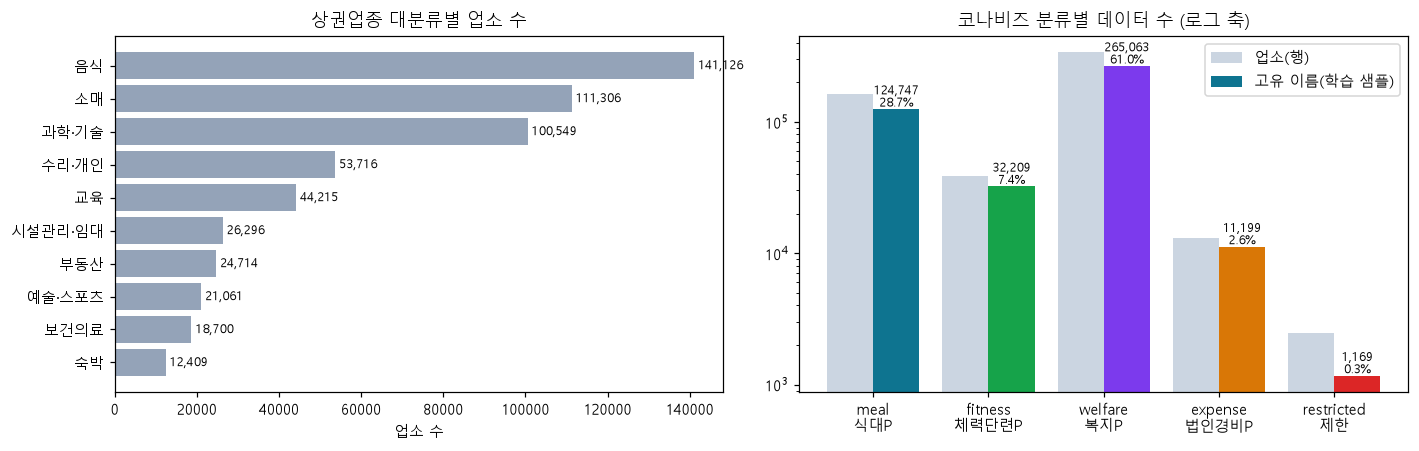

불균형: welfare / restricted = 227 : 1


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
big = raw["상권업종대분류명"].value_counts().sort_values()
axes[0].barh(big.index, big.values, color="#94A3B8")
axes[0].set_title("상권업종 대분류별 업소 수"); axes[0].set_xlabel("업소 수")
for i, v in enumerate(big.values): axes[0].text(v, i, f" {v:,}", va="center", fontsize=8)

order = list(CATEGORIES)
rows_by = raw[~raw["상호명"].eq("업소명없음")]["category"].value_counts().reindex(order)
names_by = names["category"].value_counts().reindex(order)
x = np.arange(len(order))
axes[1].bar(x - 0.2, rows_by.values, 0.4, label="업소(행)", color="#CBD5E1")
axes[1].bar(x + 0.2, names_by.values, 0.4, label="고유 이름(학습 샘플)", color=[CAT_COLOR[c] for c in order])
axes[1].set_xticks(x, [f"{c}\n{CAT_KO[c]}" for c in order]); axes[1].set_yscale("log")
axes[1].set_title("코나비즈 분류별 데이터 수 (로그 축)"); axes[1].legend()
for i, v in enumerate(names_by.values): axes[1].text(i + 0.2, v, f"{v:,}\n{v / names_by.sum():.1%}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
print(f"불균형: welfare / restricted = {names_by['welfare'] / names_by['restricted']:.0f} : 1")

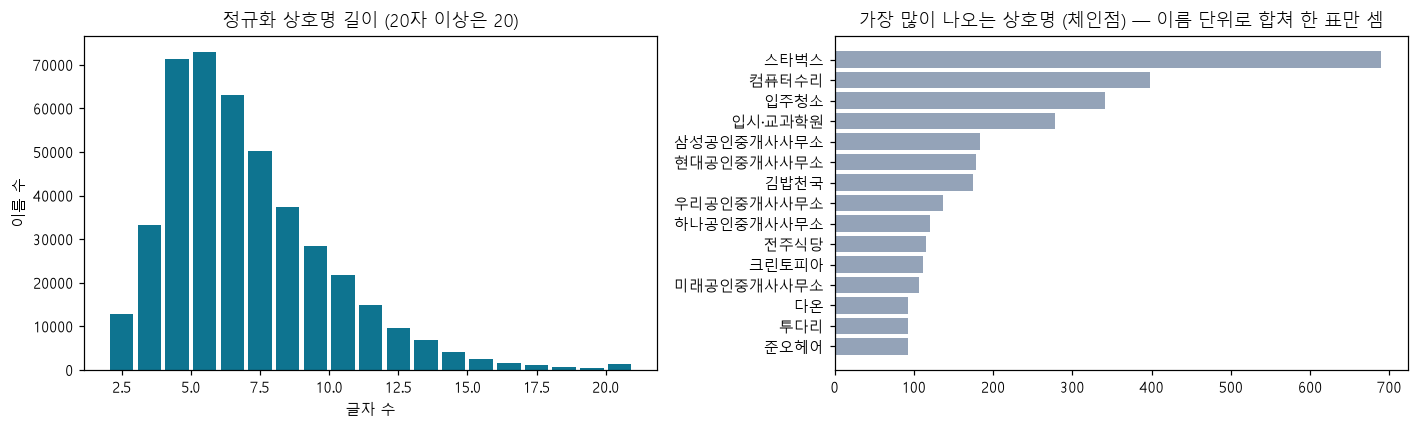

상호명 길이 중앙값 6 글자


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lens = names["key"].str.len().clip(upper=20)
axes[0].hist(lens, bins=range(2, 22), color="#0E7490", rwidth=0.85)
axes[0].set_title("정규화 상호명 길이 (20자 이상은 20)"); axes[0].set_xlabel("글자 수"); axes[0].set_ylabel("이름 수")
top = raw[~raw["상호명"].eq("업소명없음")]["상호명"].value_counts().head(15).sort_values()
axes[1].barh(top.index, top.values, color="#94A3B8")
axes[1].set_title("가장 많이 나오는 상호명 (체인점) — 이름 단위로 합쳐 한 표만 셈")
plt.tight_layout(); plt.show()
print("상호명 길이 중앙값", int(names["key"].str.len().median()), "글자")

### 변환표 (ML-1 승인본)
전체 표: `backend/ml/category_map.csv` (247개 소분류 → 근거 업종 90개 → 5분류). 아래는 분류별 요약과 소분류로 따로 뗀 업종

In [5]:
cmap = pd.read_csv(ML_DIR / "category_map.csv", encoding="utf-8-sig")
summary = cmap.groupby("코나비즈분류").agg(근거업종수=("근거업종", "nunique"), 업소수=("업소수", "sum")).reindex(order)
summary["비율"] = (summary["업소수"] / summary["업소수"].sum()).map("{:.1%}".format)
display(summary)
cmap[cmap["적용기준"] == "소분류"][["코나비즈분류", "중분류", "소분류", "업소수"]].reset_index(drop=True)

,근거업종수,업소수,비율
코나비즈분류,,,
meal,13,162363,29.3%
fitness,7,38890,7.0%
welfare,59,337333,60.9%
expense,9,13022,2.4%
restricted,2,2484,0.4%


,코나비즈분류,중분류,소분류,업소수
0,meal,오락용품 소매,서점,1524
1,fitness,기타 교육,요가/필라테스 학원,5290
2,fitness,기타 교육,태권도/무술학원,2150
3,fitness,기타 교육,레크리에이션 교육기관,939
4,fitness,의약·화장품 소매,약국,5611
5,expense,안경·정밀기기 소매,사무기기 소매업,342
6,expense,연료 소매,주유소,593
7,expense,연료 소매,가스 충전소,79
8,expense,오락용품 소매,문구/회화용품 소매업,1657
9,expense,산업용품 대여,컴퓨터/사무기기 대여업,478


## 3. 키워드 규칙 점검
서비스에서는 모델보다 먼저 적용 (`source: "rule"`).데이터의 유흥주점 이름 대부분은 '헤븐', '동경'처럼 이름만으론 알 수 없어서, 규칙은 **이름에 업태가 드러난 경우만** 확실하게 막는 용도

In [6]:
rows = []
for k in RESTRICTED_KEYWORDS:
    hit = names[names["key"].str.contains(k)]
    vc = hit["category"].value_counts()
    rows.append({"키워드": k, "적중 이름": len(hit), "데이터상 restricted": int(vc.get("restricted", 0)),
                 "데이터상 다른 분류": int(len(hit) - vc.get("restricted", 0)),
                 "다른 분류 예": ", ".join(hit[hit["category"] != "restricted"]["name"].head(3))})
rule_hit = names["key"].map(lambda k: any(w in k for w in RESTRICTED_KEYWORDS))
n_res = (names["category"] == "restricted").sum()
print(f"규칙이 덮는 restricted 이름: {(rule_hit & (names['category'] == 'restricted')).sum()} / {n_res}")
pd.DataFrame(rows)

규칙이 덮는 restricted 이름: 103 / 1169


,키워드,적중 이름,데이터상 restricted,데이터상 다른 분류,다른 분류 예
0,유흥주점,6,5,1,오페라유흥주점
1,단란주점,90,28,62,"70.80메들리단란주점, 갈채단란주점, 골목길7080라이브단란주점"
2,룸살롱,0,0,0,
3,룸싸롱,0,0,0,
4,가라오케,6,4,2,"강남가라오케, 퍼펙트가라오케"
5,노래빠,76,64,12,"별노래빠, 뽕노래빠, 성진노래빠"
6,나이트클럽,4,4,0,


> 데이터상 welfare인 '단란주점' 이름은 공공데이터에서 일반 주점으로 분류된 곳이지만, 법인카드 클린카드 기준으로는 제한 업종이라 규칙이 막는 것이 의도에 맞음

## 4. 학습 · 평가 분할
같은 브랜드가 학습과 평가에 나뉘면(예: `투다리` ↔ `투다리오금역점`) 외운 것을 맞히는 셈이라 점수가 부풀려짐.
→ **그룹 = 정규화 이름 앞 3글자**로 `StratifiedGroupKFold` 5-fold 중 1개(80/20). 같은 그룹은 한쪽에만 들어감.
비교용으로 그룹을 무시한 무작위 분할도 만듦.

In [7]:
sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, te_idx = next(sgk.split(names, names["category"], names["group"]))
train, test = names.iloc[tr_idx].reset_index(drop=True), names.iloc[te_idx].reset_index(drop=True)
r_train, r_test = train_test_split(names, test_size=0.2, stratify=names["category"], random_state=SEED)

def overlap(a, b):
    return f"{b['group'].isin(set(a['group'])).mean():.1%}"

pd.DataFrame({
    "학습": [len(train), len(r_train)], "평가": [len(test), len(r_test)],
    "평가 중 학습과 같은 그룹(앞 3글자) 비율": [overlap(train, test), overlap(r_train, r_test)],
    "평가 restricted 수": [(test["category"] == "restricted").sum(), (r_test["category"] == "restricted").sum()],
}, index=["그룹 분할 (본 평가)", "무작위 분할 (비교용)"])

,학습,평가,평가 중 학습과 같은 그룹(앞 3글자) 비율,평가 restricted 수
그룹 분할 (본 평가),347509,86878,0.0%,233
무작위 분할 (비교용),347509,86878,55.8%,234


## 5. 모델 비교
| 모델 | 설명 |
|---|---|
| **A. 업종 → 분류 합산 + LR (본 모델)** | 근거 업종 90개를 예측, 확률을 분류별로 더함 |
| B. 5분류 직접 + LR | 분류를 바로 예측 (근거 업종 없음) |
| C. 업종 → 분류 합산 + ComplementNB | 가장 단순한 확률 모델 |
| D. A + welfare 일부 추출 | welfare 이름을 6만 개만 뽑아 학습 |
| E. A를 무작위 분할로 평가 | 브랜드 누수가 있으면 점수가 얼마나 부풀려지는지 |

공통: 글자 1~3-gram TF-IDF, 평가 지표는 **macro F1** 위주

**학습 샘플 가중치 = 체인 가중치 × 분류 균형**
- 체인 가중치 `log(1 + 업소 수)` — 이름을 한 표로 합치면 스타벅스 688곳도 샘플 1개가 되어 유명 체인을 못 맞힘(1차 학습: 스타벅스 → welfare 0.41). 업소 수를 로그로 반영해 체인을 더 믿되 큰 체인이 학습을 휩쓸지 않게 함
- 분류 균형 — 체인 가중치를 곱한 뒤 분류별 가중치 합이 같아지게 맞춤 (welfare : restricted = 227 : 1 대응)
- 분할은 그대로 그룹 분할이라 같은 브랜드가 평가에 새지 않음

In [8]:
MAX_FEATURES = 50000
LR_C = 4.0
WELFARE_SAMPLE = 60_000

def make_vec():
    return TfidfVectorizer(analyzer="char", ngram_range=(1, 3), max_features=MAX_FEATURES, sublinear_tf=True, dtype=np.float32)

def balanced_weight(df):
    """체인 가중치 log(1+업소 수) × 분류 균형(분류별 가중치 합을 같게)."""
    chain = np.log1p(df["rows"].to_numpy(dtype=float))
    cat_sum = pd.Series(chain).groupby(df["category"].to_numpy()).sum()
    return chain * (chain.sum() / (len(cat_sum) * cat_sum))[df["category"]].to_numpy()

def unit_to_cat_matrix(classes, unit_cat):
    M = np.zeros((len(classes), len(CATEGORIES)), dtype=np.float32)
    for i, u in enumerate(classes): M[i, CATEGORIES.index(unit_cat[u])] = 1
    return M

UNIT_CAT = names.drop_duplicates("unit").set_index("unit")["category"].to_dict()

def fit(df, target="unit", model="lr"):
    vec = make_vec(); X = vec.fit_transform(df["key"])
    clf = LogisticRegression(C=LR_C, max_iter=400) if model == "lr" else ComplementNB(alpha=0.3)
    clf.fit(X, df[target], sample_weight=balanced_weight(df))
    if model == "lr": clf.coef_ = clf.coef_.astype(np.float32); clf.intercept_ = clf.intercept_.astype(np.float32)
    return vec, clf

def predict_cat(vec, clf, keys):
    P = clf.predict_proba(vec.transform(keys))
    if set(clf.classes_) <= set(CATEGORIES):  # 5분류 직접
        PC = P[:, [list(clf.classes_).index(c) for c in CATEGORIES]]; units = None
    else:
        M = unit_to_cat_matrix(clf.classes_, UNIT_CAT); PC = P @ M
        cat_i = PC.argmax(1)
        masked = np.where(M[:, cat_i].T > 0, P, -1)  # 고른 분류 안에서 최고 업종
        units = clf.classes_[masked.argmax(1)]
    cat_i = PC.argmax(1)
    return np.array(CATEGORIES)[cat_i], PC.max(1), units

def size_mb(obj):
    buf = io.BytesIO(); joblib.dump(obj, buf, compress=3); return buf.tell() / 1e6

def evaluate(label, df_tr, df_te, **kw):
    t = time.time(); vec, clf = fit(df_tr, **kw); sec = time.time() - t
    pred, conf, units = predict_cat(vec, clf, df_te["key"])
    f1s = f1_score(df_te["category"], pred, labels=list(CATEGORIES), average=None)
    row = {"모델": label, "정확도": accuracy_score(df_te["category"], pred), "macro F1": f1_score(df_te["category"], pred, average="macro"),
           **{f"F1 {c}": v for c, v in zip(CATEGORIES, f1s)}, "학습(초)": round(sec), "크기(MB)": round(size_mb((vec, clf)), 1)}
    return row, (vec, clf, pred, conf, units)

welfare_part = train[train["category"] == "welfare"].sample(WELFARE_SAMPLE, random_state=SEED)
train_d = pd.concat([train[train["category"] != "welfare"], welfare_part])

results, runs = [], {}
for label, a, b, kw in [
    ("A. 업종 합산 + LR (본 모델)", train, test, {}),
    ("B. 5분류 직접 + LR", train, test, {"target": "category"}),
    ("C. 업종 합산 + ComplementNB", train, test, {"model": "nb"}),
    ("D. A + welfare 6만 추출", train_d, test, {}),
    ("E. A · 무작위 분할(누수)", r_train, r_test, {}),
]:
    row, runs[label[0]] = evaluate(label, a, b, **kw); results.append(row); print(label, "완료", row["학습(초)"], "초")

res = pd.DataFrame(results).set_index("모델")
res.style.format({c: "{:.3f}" for c in res.columns if c.startswith(("정확도", "macro", "F1"))}).background_gradient(subset=["macro F1"], cmap="Greens")

A. 업종 합산 + LR (본 모델) 완료 432 초


B. 5분류 직접 + LR 완료 49 초


C. 업종 합산 + ComplementNB 완료 10 초


D. A + welfare 6만 추출 완료 311 초


E. A · 무작위 분할(누수) 완료 460 초


,정확도,macro F1,F1 meal,F1 fitness,F1 welfare,F1 expense,F1 restricted,학습(초),크기(MB)
모델,,,,,,,,,
A. 업종 합산 + LR (본 모델),0.834,0.647,0.804,0.901,0.872,0.479,0.178,432,16.800000
B. 5분류 직접 + LR,0.820,0.631,0.798,0.890,0.860,0.421,0.185,49,1.400000
C. 업종 합산 + ComplementNB,0.697,0.523,0.217,0.759,0.801,0.434,0.402,10,38.500000
D. A + welfare 6만 추출,0.816,0.627,0.794,0.898,0.856,0.441,0.148,311,16.500000
E. A · 무작위 분할(누수),0.841,0.652,0.813,0.902,0.877,0.501,0.167,460,16.800000


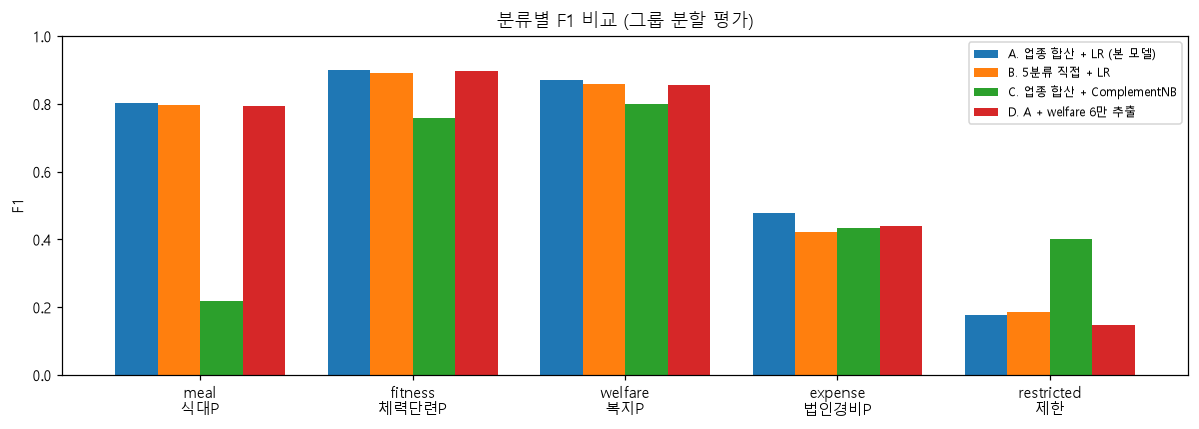

In [9]:
ax = res[[f"F1 {c}" for c in CATEGORIES]].iloc[:4].T.plot(kind="bar", figsize=(11, 4), rot=0, width=0.8)
ax.set_xticklabels([f"{c}\n{CAT_KO[c]}" for c in CATEGORIES]); ax.set_ylabel("F1"); ax.set_ylim(0, 1)
ax.set_title("분류별 F1 비교 (그룹 분할 평가)"); ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

### 체인 가중치 적용 전후 (모델 A, 같은 그룹 분할)
'적용 전'은 1차 학습(분류 균형 가중치만) 노트북 실행 결과를 그대로 옮긴 값

In [10]:
BEFORE = {"정확도": 0.836, "macro F1": 0.650, "F1 meal": 0.804, "F1 fitness": 0.899, "F1 welfare": 0.873, "F1 expense": 0.488, "F1 restricted": 0.186}
after = res.loc["A. 업종 합산 + LR (본 모델)", list(BEFORE)]
cmp = pd.DataFrame({"적용 전 (1차)": BEFORE, "적용 후 (체인 가중치)": after.astype(float)})
cmp["차이"] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
cmp.style.format("{:.3f}").format("{:+.3f}", subset=["차이"])

,적용 전 (1차),적용 후 (체인 가중치),차이
정확도,0.836,0.834,-0.002
macro F1,0.650,0.647,-0.003
F1 meal,0.804,0.804,-0.000
F1 fitness,0.899,0.901,+0.002
F1 welfare,0.873,0.872,-0.001
F1 expense,0.488,0.479,-0.009
F1 restricted,0.186,0.178,-0.008


## 6. 본 모델(A) 상세

In [11]:
vec_a, clf_a, pred_a, conf_a, units_a = runs["A"]
print(classification_report(test["category"], pred_a, labels=list(CATEGORIES), digits=3))

# 서비스와 같은 판정 (규칙 → 모델) 이었을 때 restricted
rule_on = test["key"].map(lambda k: rule_category(k) is not None).to_numpy()
pred_rule = np.where(rule_on, "restricted", pred_a)
is_r = test["category"].to_numpy() == "restricted"
print(f"[참고] 규칙 포함 시 restricted — recall {(pred_rule[is_r] == 'restricted').mean():.3f} "
      f"(모델만 {(pred_a[is_r] == 'restricted').mean():.3f}), 규칙 적중 {rule_on.sum()}건")

              precision    recall  f1-score   support

        meal      0.799     0.808     0.804     24950
     fitness      0.880     0.922     0.901      6442
     welfare      0.903     0.843     0.872     53013
     expense      0.368     0.683     0.479      2240
  restricted      0.106     0.567     0.178       233

    accuracy                          0.834     86878
   macro avg      0.611     0.765     0.647     86878
weighted avg      0.855     0.834     0.842     86878



[참고] 규칙 포함 시 restricted — recall 0.567 (모델만 0.567), 규칙 적중 45건


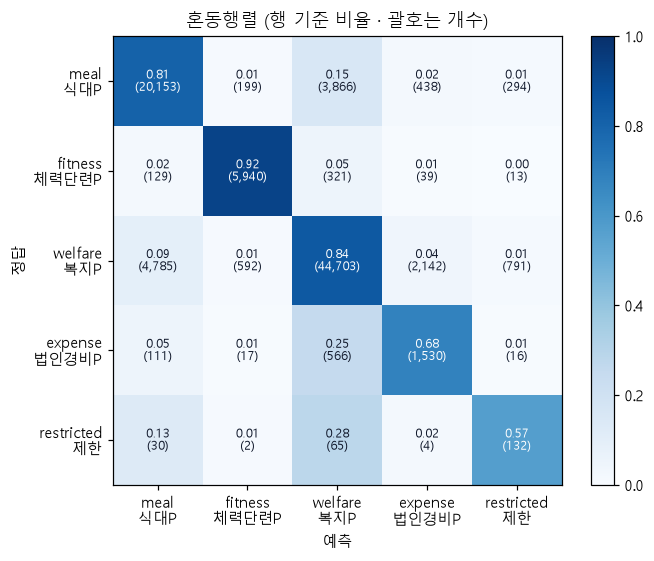

In [12]:
cm = confusion_matrix(test["category"], pred_a, labels=list(CATEGORIES))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
labels = [f"{c}\n{CAT_KO[c]}" for c in CATEGORIES]
ax.set_xticks(range(5), labels); ax.set_yticks(range(5), labels)
ax.set_xlabel("예측"); ax.set_ylabel("정답"); ax.set_title("혼동행렬 (행 기준 비율 · 괄호는 개수)")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]:,})", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "#0F172A")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

### 확신도 구간별 정확도 → '확신도 낮음' 기준값

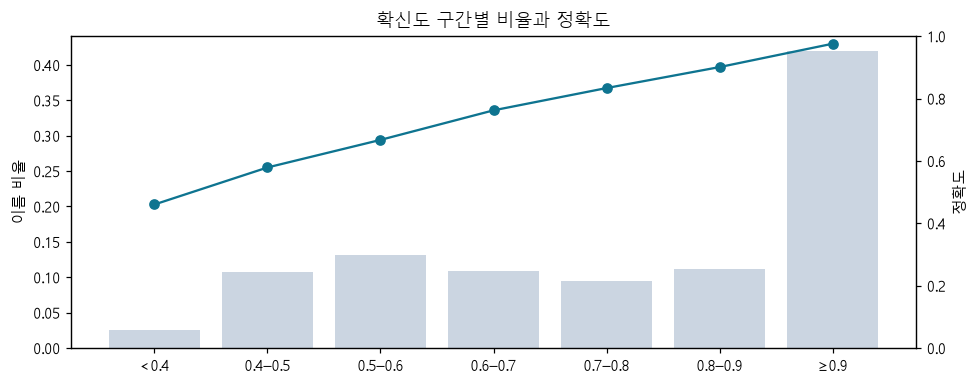

기준 0.5: 확신도 이상 86.6% — 그 안 정확도 0.877 / 미만 정확도 0.556
기준 0.6: 확신도 이상 73.4% — 그 안 정확도 0.915 / 미만 정확도 0.611
기준 0.7: 확신도 이상 62.6% — 그 안 정확도 0.941 / 미만 정확도 0.655


,이름수,정확도,비율
band,,,
<0.4,2231,0.460,2.6%
0.4–0.5,9392,0.579,10.8%
0.5–0.6,11449,0.667,13.2%
0.6–0.7,9401,0.762,10.8%
0.7–0.8,8203,0.834,9.4%
0.8–0.9,9742,0.901,11.2%
≥0.9,36460,0.976,42.0%


In [13]:
bins = [0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
band = pd.cut(conf_a, bins, right=False, labels=["<0.4", "0.4–0.5", "0.5–0.6", "0.6–0.7", "0.7–0.8", "0.8–0.9", "≥0.9"])
ok = pred_a == test["category"].to_numpy()
cal = pd.DataFrame({"band": band, "ok": ok}).groupby("band", observed=False).agg(이름수=("ok", "size"), 정확도=("ok", "mean"))
cal["비율"] = cal["이름수"] / cal["이름수"].sum()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(cal.index.astype(str), cal["비율"], color="#CBD5E1", label="이름 비율")
ax2 = ax.twinx(); ax2.plot(cal.index.astype(str), cal["정확도"], "o-", color="#0E7490", label="정확도"); ax2.set_ylim(0, 1)
ax.set_title("확신도 구간별 비율과 정확도"); ax.set_ylabel("이름 비율"); ax2.set_ylabel("정확도")
plt.tight_layout(); plt.show()
for th in (0.5, 0.6, 0.7):
    m = conf_a >= th
    print(f"기준 {th}: 확신도 이상 {m.mean():.1%} — 그 안 정확도 {ok[m].mean():.3f} / 미만 정확도 {ok[~m].mean():.3f}")
cal.style.format({"정확도": "{:.3f}", "비율": "{:.1%}"})

### 확신도 기준별 restricted · expense (화면 정책용)
모델 판정만 (`source: "model"`). 모델이 그 분류로 판정했고 확신도가 기준 이상인 것만 셈 → precision = 그중 정답 비율, recall = 정답 전체 중 잡은 비율. 키워드 규칙 판정은 맨 아래 행에 따로

In [14]:
def threshold_table(cat, ths=(0.0, 0.5, 0.6, 0.7, 0.8, 0.9)):
    truth = test["category"].to_numpy() == cat
    rows = []
    for th in ths:
        hit = (pred_a == cat) & (conf_a >= th)
        rows.append({"기준": "전체(기준 없음)" if th == 0 else f"≥ {th}", "판정 건수": int(hit.sum()), "그중 정답": int((hit & truth).sum()),
                     "precision": (hit & truth).sum() / max(hit.sum(), 1), "recall": (hit & truth).sum() / truth.sum()})
    return pd.DataFrame(rows).set_index("기준")

r_tab = threshold_table("restricted")
truth_r = test["category"].to_numpy() == "restricted"
r_tab.loc["키워드 규칙 (별도)"] = [int(rule_on.sum()), int((rule_on & truth_r).sum()), (rule_on & truth_r).sum() / max(rule_on.sum(), 1), (rule_on & truth_r).sum() / truth_r.sum()]
print(f"restricted 평가 정답 {truth_r.sum()}개")
display(r_tab.style.format({"precision": "{:.3f}", "recall": "{:.3f}"}))
print(f"expense 평가 정답 {(test['category'] == 'expense').sum()}개")
threshold_table("expense").style.format({"precision": "{:.3f}", "recall": "{:.3f}"})

restricted 평가 정답 233개


,판정 건수,그중 정답,precision,recall
기준,,,,
전체(기준 없음),1246.000000,132.000000,0.106,0.567
≥ 0.5,888.000000,127.000000,0.143,0.545
≥ 0.6,715.000000,123.000000,0.172,0.528
≥ 0.7,551.000000,118.000000,0.214,0.506
≥ 0.8,420.000000,110.000000,0.262,0.472
≥ 0.9,288.000000,101.000000,0.351,0.433
키워드 규칙 (별도),45.000000,30.000000,0.667,0.129


expense 평가 정답 2240개


,판정 건수,그중 정답,precision,recall
기준,,,,
전체(기준 없음),4153,1530,0.368,0.683
≥ 0.5,3182,1468,0.461,0.655
≥ 0.6,2505,1411,0.563,0.630
≥ 0.7,2028,1360,0.671,0.607
≥ 0.8,1688,1298,0.769,0.579
≥ 0.9,1376,1208,0.878,0.539


In [15]:
PREV_06 = {"확신도 0.6 이상 비율": 0.752, "그 안 정확도": 0.912, "0.6 미만 정확도": 0.604}
m = conf_a >= 0.6
now = {"확신도 0.6 이상 비율": m.mean(), "그 안 정확도": ok[m].mean(), "0.6 미만 정확도": ok[~m].mean()}
pd.DataFrame({"적용 전 (1차)": PREV_06, "적용 후": now}).style.format("{:.3f}")

,적용 전 (1차),적용 후
확신도 0.6 이상 비율,0.752,0.734
그 안 정확도,0.912,0.915
0.6 미만 정확도,0.604,0.611


## 7. 틀린 사례 (확신도 높게 틀린 15개 + 무작위 15개)

In [16]:
err = test.assign(pred=pred_a, conf=conf_a, pred_unit=units_a)[~ok]
wrong = pd.concat([err.nlargest(15, "conf"), err.drop(err.nlargest(15, "conf").index).sample(15, random_state=SEED)])
wrong = wrong.assign(정답=wrong["category"] + " · " + wrong["unit"], 예측=wrong["pred"] + " · " + wrong["pred_unit"])
wrong[["name", "정답", "예측", "conf"]].rename(columns={"name": "상호명", "conf": "확신도"}).reset_index(drop=True).style.format({"확신도": "{:.2f}"})

,상호명,정답,예측,확신도
0,웰투어,welfare · 기타 전문 과학,expense · 여행사·보조,1.00
1,달커피숖,welfare · 주점,meal · 비알코올,1.00
2,레저캠프여행사주,welfare · 오락용품 소매,expense · 여행사·보조,1.00
3,올E문구,welfare · 전문 디자인,expense · 문구/회화용품 소매업,1.00
4,카존렌트카,welfare · 기타 전문 과학,expense · 자동차 대여업,1.00
5,파랑약국,welfare · 식료품 소매,fitness · 약국,1.00
6,커피넷,welfare · 산업용품 대여,meal · 비알코올,1.00
7,로얄레저앤트래블,welfare · 광고,expense · 여행사·보조,1.00
8,씨유빈,meal · 비알코올,welfare · 종합 소매,1.00
9,빙구문구,welfare · 종합 소매,expense · 문구/회화용품 소매업,1.00


### 틀린 사례 해석

| 유형 | 예 | 왜 틀렸나 |
|---|---|---|
| **① 정답(공공데이터 업종)이 이름과 안 맞음** — 확신도 높은 오답 대부분 | 방배우리내과의원 · 가장편한내과의원 · 파랑약국(정답 식료품 소매), 웰투어 · 카존렌트카(정답 기타 전문 과학) | 등록 업종이 실제 영업과 다르거나 잘못 입력된 경우. 모델 예측(의원 · 약국 · 여행사 · 렌터카)이 오히려 상식에 맞음 → 평가 점수가 실제보다 낮게 나오는 원인 |
| **② 이름에 업종 단어가 있지만 실제 업종은 다름** | 달커피숖(정답 주점), 커피넷(산업용품 대여), 빙구문구(종합 소매), 제이블랑필라테스(욕탕·신체관리) | 글자 n-gram은 '커피' · '문구' · '필라테스' 같은 단어를 강하게 믿음. 이름만 보는 모델의 본질적 한계 |
| **③ 다른 브랜드와 글자가 겹침** | 씨유빈(정답 카페 → 예측 종합 소매) | '씨유'(편의점 CU)와 같은 글자 조합 |
| **④ 노래방·주점 ↔ 유흥주점** | 광장노래노래(정답 노래방), 몽노래바큐(정답 주점) → 둘 다 일반 유흥 주점 1.00 · 반대로 발리투(정답 유흥주점) → 여행사 0.90 | '노래' · '바'가 노래빠 이름과 겹침. 실제 유흥주점 이름은 업태 단서가 없어 '발리'(여행지)처럼 다른 단어에 끌려감 |
| **⑤ 업종 단서가 없는 브랜드형 이름** | 페이머스 · 나이스이즈굿 · 에피코퍼레이티드 · 곤로 · 멜리사앤파코 | 이름만으로는 사람도 알 수 없음. 확신도가 0.35~0.56으로 낮게 나와서 서비스에서는 '확신도 낮음'으로 표시해 구분 가능 |

**정리**: 확신도 높은 오답은 주로 데이터 라벨 문제(①)이고, 모델이 어려워하는 경우(⑤)는 확신도가 낮게 나옴 → 확신도 기준값으로 사용자에게 알릴 수 있음. 다만 restricted는 높은 확신도에서도 오답(④)이 많아 기준값만으로는 부족함

## 8. 데모 상호명 (서비스와 같은 판정: 규칙 → 모델)
체인점 · 처음 보는 이름 · 애매한 이름. 이 단계의 예측은 평가용 모델(A, 학습 80%)

In [17]:
DEMO = ["스타벅스", "스타벅스 강남점", "애니타임피트니스", "OO 유흥주점", "오피스디포", "김밥천국", "한솥도시락", "라운지바 강남",
        "달빛우동 성수점", "새벽별문구", "교보문고", "다이소 강남점", "올리브영 신촌점"]
bundle_eval = {"vectorizer": vec_a, "clf": clf_a, "unit_category": UNIT_CAT}
demo = pd.DataFrame([{"상호명": n, **classify(bundle_eval, n)} for n in DEMO])
demo["포인트"] = demo["category"].map(CAT_KO)
rows_by_key = names.set_index("key")["rows"]
demo["학습 데이터 같은 이름 업소 수"] = demo["상호명"].map(lambda n: int(rows_by_key.get(normalize(n), 0)))
demo.style.format({"confidence": "{:.2f}"})

,상호명,category,confidence,industry,source,포인트,학습 데이터 같은 이름 업소 수
0,스타벅스,meal,0.58,비알코올,model,식대P,688
1,스타벅스 강남점,meal,0.66,비알코올,model,식대P,0
2,애니타임피트니스,fitness,1.00,스포츠 서비스,model,체력단련P,2
3,OO 유흥주점,restricted,1.00,유흥주점 키워드,rule,제한,0
4,오피스디포,expense,0.99,문구/회화용품 소매업,model,법인경비P,5
5,김밥천국,meal,0.99,기타 간이,model,식대P,175
6,한솥도시락,meal,1.00,한식,model,식대P,24
7,라운지바 강남,meal,0.43,서양식,model,식대P,0
8,달빛우동 성수점,meal,0.94,일식,model,식대P,0
9,새벽별문구,expense,0.99,문구/회화용품 소매업,model,법인경비P,0


## 9. 최종 모델 학습 · 저장
평가를 마친 설정(A)으로 **전체 이름**을 다시 학습해 `backend/ml/models/`에 저장. 서버는 이 파일을 시작할 때 한 번만 불러옴

In [18]:
t = time.time()
vec_f, clf_f = fit(names)
MODEL_DIR = ML_DIR / "models"; MODEL_DIR.mkdir(exist_ok=True)
bundle = {"vectorizer": vec_f, "clf": clf_f, "unit_category": UNIT_CAT, "categories": list(CATEGORIES)}
joblib.dump(bundle, MODEL_DIR / "merchant_classifier.joblib", compress=3)
best = res.loc["A. 업종 합산 + LR (본 모델)"]
meta = {
    "model": "char 1-3gram TF-IDF + LogisticRegression (근거 업종 → 코나비즈 분류 합산)",
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "python": platform.python_version(), "scikit_learn": sklearn.__version__, "numpy": np.__version__, "joblib": joblib.__version__,
    "data": DATA_CSV.name, "train_names": len(names), "units": len(UNIT_CAT),
    "params": {"max_features": MAX_FEATURES, "C": LR_C, "ngram_range": [1, 3], "sample_weight": "log1p(업소 수) 체인 가중치 × 분류 균형(분류별 합 동일)"},
    "eval_group_split": {"accuracy": round(best["정확도"], 4), "macro_f1": round(best["macro F1"], 4),
                         **{f"f1_{c}": round(best[f'F1 {c}'], 4) for c in CATEGORIES}},
    "restricted_keywords": list(RESTRICTED_KEYWORDS),
}
(MODEL_DIR / "model_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"{time.time() - t:.0f}초 · 모델 파일 {(MODEL_DIR / 'merchant_classifier.joblib').stat().st_size / 1e6:.1f} MB")
meta

606초 · 모델 파일 16.9 MB


{'model': 'char 1-3gram TF-IDF + LogisticRegression (근거 업종 → 코나비즈 분류 합산)',
 'trained_at': '2026-10-21T02:18:34+00:00',
 'python': '3.12.9',
 'scikit_learn': '1.9.1',
 'numpy': '2.5.4',
 'joblib': '1.6.0',
 'data': '소상공인시장진흥공단_상가(상권)정보_서울_202606.csv',
 'train_names': 434387,
 'units': 90,
 'params': {'max_features': 50000,
  'C': 4.0,
  'ngram_range': [1, 3],
  'sample_weight': 'log1p(업소 수) 체인 가중치 × 분류 균형(분류별 합 동일)'},
 'eval_group_split': {'accuracy': np.float64(0.834),
  'macro_f1': np.float64(0.6466),
  'f1_meal': np.float64(0.8036),
  'f1_fitness': np.float64(0.9005),
  'f1_welfare': np.float64(0.872),
  'f1_expense': np.float64(0.4786),
  'f1_restricted': np.float64(0.1785)},
 'restricted_keywords': ['유흥주점', '단란주점', '룸살롱', '룸싸롱', '가라오케', '노래빠', '나이트클럽']}

In [19]:
# 저장한 파일을 다시 불러와 서비스와 같은 함수로 확인
loaded = joblib.load(MODEL_DIR / "merchant_classifier.joblib")
pd.DataFrame([{"상호명": n, **classify(loaded, n)} for n in DEMO]).style.format({"confidence": "{:.2f}"})

,상호명,category,confidence,industry,source
0,스타벅스,meal,0.54,비알코올,model
1,스타벅스 강남점,meal,0.63,비알코올,model
2,애니타임피트니스,fitness,1.00,스포츠 서비스,model
3,OO 유흥주점,restricted,1.00,유흥주점 키워드,rule
4,오피스디포,expense,1.00,문구/회화용품 소매업,model
5,김밥천국,meal,1.00,기타 간이,model
6,한솥도시락,meal,1.00,한식,model
7,라운지바 강남,restricted,0.53,일반 유흥 주점,model
8,달빛우동 성수점,meal,0.94,일식,model
9,새벽별문구,expense,0.99,문구/회화용품 소매업,model
